# Demand Prediction

## Project: Retail Pricing, Demand & Profitability Decision Model

### Objective
To develop machine-learning models that can predict retail demand using historical pricing, inventory, promotional, seasonal and other relevant business variables.

### Business Questions
1. Can we predict future retail demand using historical data?
2. Which variables are most useful for predicting demand?
3. How accurately can machine-learning models estimate demand?
4. Which model performs best?
5. How can demand predictions support inventory and pricing decisions?

### Analysis Approach
This notebook will use Python, Pandas, NumPy and Scikit-learn to prepare data, select relevant features, train prediction models and evaluate their performance.

### Expected Outcome
A tested demand prediction model that estimates retail demand and provides insights into the factors associated with demand patterns.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../Data/Raw/retail_demand.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (76000, 16)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [2]:
print("Dataset information:")
df.info()

print("\nTarget variable:")
print("Demand")

print("\nAvailable columns:")
print(df.columns.tolist())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                76000 non-null  str    
 1   Store ID            76000 non-null  str    
 2   Product ID          76000 non-null  str    
 3   Category            76000 non-null  str    
 4   Region              76000 non-null  str    
 5   Inventory Level     76000 non-null  int64  
 6   Units Sold          76000 non-null  int64  
 7   Units Ordered       76000 non-null  int64  
 8   Price               76000 non-null  float64
 9   Discount            76000 non-null  int64  
 10  Weather Condition   76000 non-null  str    
 11  Promotion           76000 non-null  int64  
 12  Competitor Pricing  76000 non-null  float64
 13  Seasonality         76000 non-null  str    
 14  Epidemic            76000 non-null  int64  
 15  Demand              76000 non-null  int64  

In [3]:
prediction_features = [
    "Store ID",
    "Product ID",
    "Category",
    "Region",
    "Inventory Level",
    "Price",
    "Discount",
    "Weather Condition",
    "Promotion",
    "Competitor Pricing",
    "Seasonality",
    "Epidemic"
]

target = "Demand"

print("Prediction features:")
for feature in prediction_features:
    print("-", feature)

print("\nTarget variable:", target)
print("\nNumber of features:", len(prediction_features))

Prediction features:
- Store ID
- Product ID
- Category
- Region
- Inventory Level
- Price
- Discount
- Weather Condition
- Promotion
- Competitor Pricing
- Seasonality
- Epidemic

Target variable: Demand

Number of features: 12


In [4]:
X = df[prediction_features]
y = df[target]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

display(X.head())
display(y.head())

Features (X) shape: (76000, 12)
Target (y) shape: (76000,)


,Store ID,Product ID,Category,Region,Inventory Level,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic
0,S001,P0001,Electronics,North,195,72.72,5,Snowy,0,85.73,Winter,0
1,S001,P0002,Clothing,North,117,80.16,15,Snowy,1,92.02,Winter,0
2,S001,P0003,Clothing,North,247,62.94,10,Snowy,1,60.08,Winter,0
3,S001,P0004,Electronics,North,139,87.63,10,Snowy,0,85.19,Winter,0
4,S001,P0005,Groceries,North,152,54.41,0,Snowy,0,51.63,Winter,0


0    115
1    229
2    157
3     52
4     59
Name: Demand, dtype: int64

In [5]:
categorical_features = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['Store ID', 'Product ID', 'Category', 'Region', 'Weather Condition', 'Seasonality']

Numerical features:
['Inventory Level', 'Price', 'Discount', 'Promotion', 'Competitor Pricing', 'Epidemic']


In [6]:
X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

print("Original feature shape:", X.shape)
print("Encoded feature shape:", X_encoded.shape)

display(X_encoded.head())

Original feature shape: (76000, 12)
Encoded feature shape: (76000, 42)


,Inventory Level,Price,Discount,Promotion,Competitor Pricing,Epidemic,Store ID_S002,Store ID_S003,Store ID_S004,Store ID_S005,...,Category_Toys,Region_North,Region_South,Region_West,Weather Condition_Rainy,Weather Condition_Snowy,Weather Condition_Sunny,Seasonality_Spring,Seasonality_Summer,Seasonality_Winter
0,195,72.72,5,0,85.73,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,1
1,117,80.16,15,1,92.02,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,1
2,247,62.94,10,1,60.08,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,1
3,139,87.63,10,0,85.19,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,1
4,152,54.41,0,0,51.63,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,1


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (60800, 42)
Testing features: (15200, 42)
Training target: (60800,)
Testing target: (15200,)


In [8]:
from sklearn.linear_model import LinearRegression

# Create the model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [9]:
# Predict demand using testing data
y_pred = linear_model.predict(X_test)

print("Demand predictions generated successfully!")

print("\nFirst 10 actual demand values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted demand values:")
print(y_pred[:10].round(2))


Demand predictions generated successfully!

First 10 actual demand values:
[111  81  37 152 101 137 127 163 164 111]

First 10 predicted demand values:
[ 99.44  81.6   42.38 111.04  89.89 100.   144.7  132.24 158.38 137.55]


In [10]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Evaluation")
print("-----------------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R-squared:", round(r2, 4))

Linear Regression Model Evaluation
-----------------------------------
MAE: 26.45
MSE: 1175.81
RMSE: 34.29
R-squared: 0.4676


In [11]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [12]:
# Predict demand using Random Forest
rf_pred = rf_model.predict(X_test)

print("Random Forest predictions generated successfully!")

print("\nFirst 10 actual demand values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted demand values:")
print(rf_pred[:10].round(2))

Random Forest predictions generated successfully!

First 10 actual demand values:
[111  81  37 152 101 137 127 163 164 111]

First 10 predicted demand values:
[106.97  85.45  32.38 125.57  99.88 110.64 131.25 155.13 140.47 123.48]


In [13]:
rf_mae = mean_absolute_error(y_test, rf_pred)

rf_mse = mean_squared_error(y_test, rf_pred)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Model Evaluation")
print("--------------------------------")
print("MAE:", round(rf_mae, 2))
print("MSE:", round(rf_mse, 2))
print("RMSE:", round(rf_rmse, 2))
print("R-squared:", round(rf_r2, 4))

Random Forest Model Evaluation
--------------------------------
MAE: 16.96
MSE: 567.4
RMSE: 23.82
R-squared: 0.7431


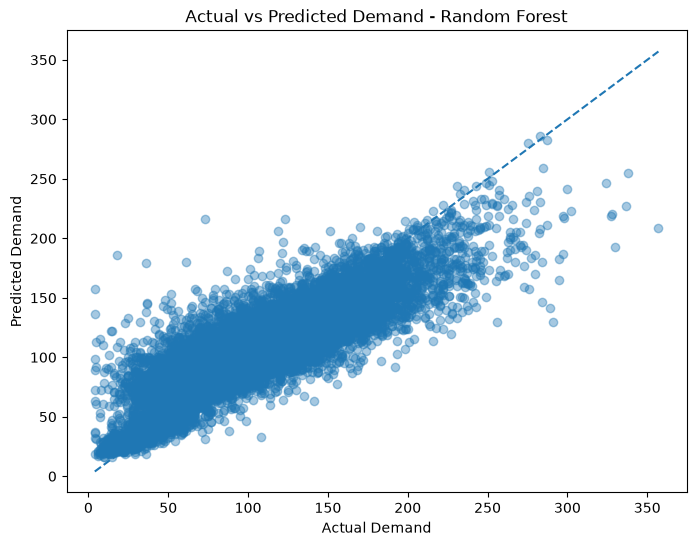

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred, alpha=0.4)

plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")
plt.title("Actual vs Predicted Demand - Random Forest")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

In [15]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
1,Price,0.184829
5,Epidemic,0.170775
3,Promotion,0.105941
30,Category_Furniture,0.094750
31,Category_Groceries,0.083461
4,Competitor Pricing,0.042408
32,Category_Toys,0.042326
38,Weather Condition_Sunny,0.025318
40,Seasonality_Summer,0.024435
2,Discount,0.020839


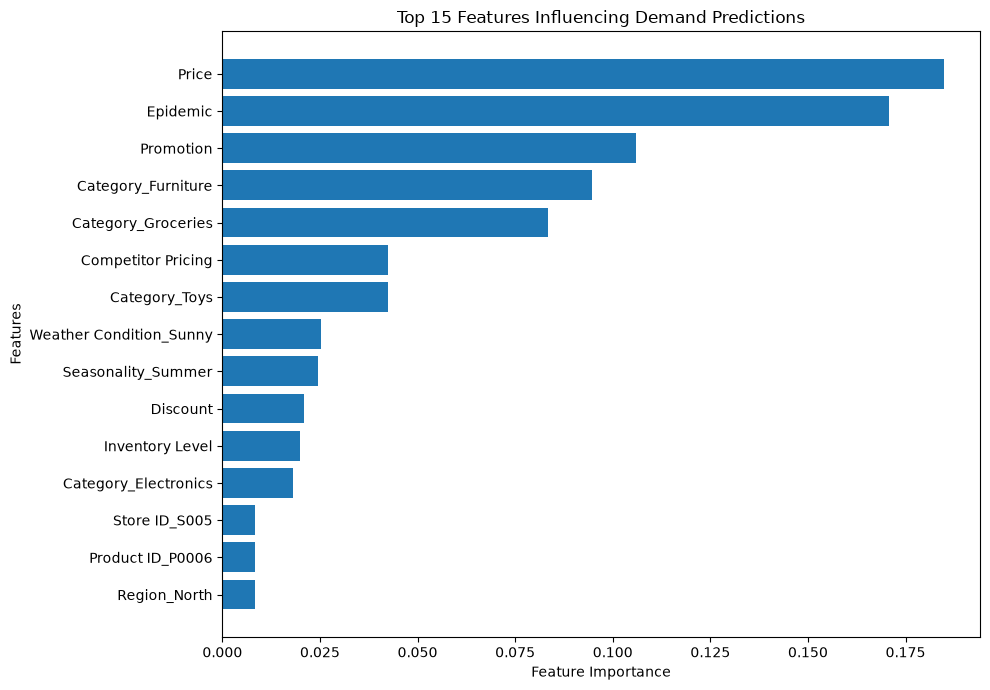

In [16]:
top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Features Influencing Demand Predictions")

plt.tight_layout()
plt.show()

,Model,MAE,RMSE,R2
0,Linear Regression,26.451319,34.290023,0.467604
1,Random Forest,16.962316,23.820140,0.743086


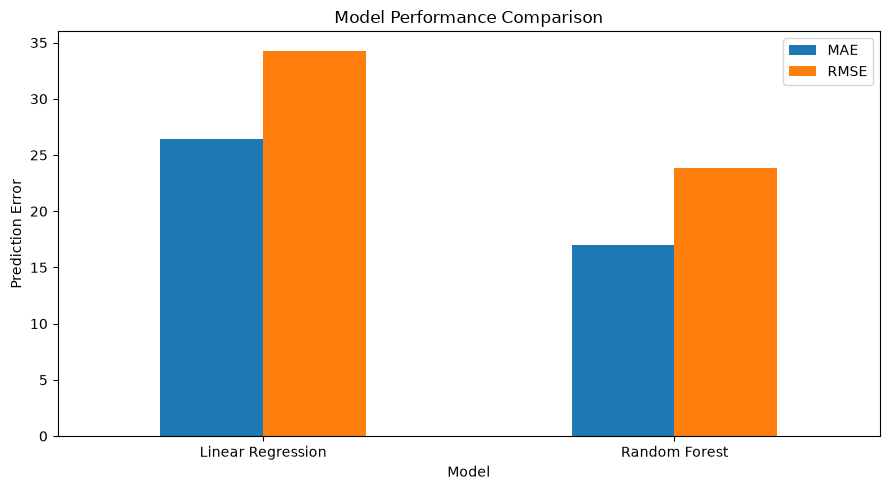

In [17]:
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2": [r2, rf_r2]
})

display(model_comparison)

model_comparison.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Prediction Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
df["Date"] = pd.to_datetime(df["Date"])

print("Earliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())
print("Unique dates:", df["Date"].nunique())

Earliest date: 2022-01-01 00:00:00
Latest date: 2024-01-30 00:00:00
Unique dates: 760


In [19]:
df = df.sort_values(by="Date").reset_index(drop=True)

print("Dataset sorted chronologically!")
display(df[["Date", "Demand"]].head())
display(df[["Date", "Demand"]].tail())

Dataset sorted chronologically!


,Date,Demand
0,2022-01-01,115
1,2022-01-01,110
2,2022-01-01,103
3,2022-01-01,61
4,2022-01-01,128


,Date,Demand
75995,2024-01-30,96
75996,2024-01-30,109
75997,2024-01-30,118
75998,2024-01-30,105
75999,2024-01-30,73


In [20]:
split_date = df["Date"].sort_values().unique()[
    int(len(df["Date"].unique()) * 0.80)
]

train_df = df[df["Date"] < split_date].copy()
test_df = df[df["Date"] >= split_date].copy()

print("Split date:", split_date)
print("Training period:", train_df["Date"].min(), "to", train_df["Date"].max())
print("Testing period:", test_df["Date"].min(), "to", test_df["Date"].max())

print("\nTraining records:", len(train_df))
print("Testing records:", len(test_df))

Split date: 2023-09-01 00:00:00
Training period: 2022-01-01 00:00:00 to 2023-08-31 00:00:00
Testing period: 2023-09-01 00:00:00 to 2024-01-30 00:00:00

Training records: 60800
Testing records: 15200


In [21]:
X_train_time = train_df[prediction_features]
y_train_time = train_df[target]

X_test_time = test_df[prediction_features]
y_test_time = test_df[target]

print("Training features:", X_train_time.shape)
print("Testing features:", X_test_time.shape)

print("Training target:", y_train_time.shape)
print("Testing target:", y_test_time.shape)

Training features: (60800, 12)
Testing features: (15200, 12)
Training target: (60800,)
Testing target: (15200,)


In [22]:
X_train_time_encoded = pd.get_dummies(
    X_train_time,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

X_test_time_encoded = pd.get_dummies(
    X_test_time,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

X_test_time_encoded = X_test_time_encoded.reindex(
    columns=X_train_time_encoded.columns,
    fill_value=0
)

print("Training encoded shape:", X_train_time_encoded.shape)
print("Testing encoded shape:", X_test_time_encoded.shape)

Training encoded shape: (60800, 42)
Testing encoded shape: (15200, 42)


In [23]:
rf_time_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_time_model.fit(
    X_train_time_encoded,
    y_train_time
)

print("Chronological Random Forest model trained successfully!")

Chronological Random Forest model trained successfully!


In [24]:
rf_time_pred = rf_time_model.predict(X_test_time_encoded)

print("First 10 actual demand values:")
print(y_test_time.head(10).values)

print("\nFirst 10 predicted demand values:")
print(rf_time_pred[:10].round(2))

First 10 actual demand values:
[182 102 150 117 134 145  89 106 102 176]

First 10 predicted demand values:
[169.03 123.85 119.26 139.77 150.61 106.86  91.99 112.6  128.14 174.95]


In [25]:
time_mae = mean_absolute_error(y_test_time, rf_time_pred)

time_mse = mean_squared_error(y_test_time, rf_time_pred)

time_rmse = np.sqrt(time_mse)

time_r2 = r2_score(y_test_time, rf_time_pred)

print("Chronological Random Forest Evaluation")
print("---------------------------------------")
print("MAE:", round(time_mae, 2))
print("MSE:", round(time_mse, 2))
print("RMSE:", round(time_rmse, 2))
print("R-squared:", round(time_r2, 4))

Chronological Random Forest Evaluation
---------------------------------------
MAE: 16.0
MSE: 499.17
RMSE: 22.34
R-squared: 0.7432


In [26]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression (Random Split)",
        "Random Forest (Random Split)",
        "Random Forest (Chronological Split)"
    ],
    "MAE": [mae, rf_mae, time_mae],
    "RMSE": [rmse, rf_rmse, time_rmse],
    "R2": [r2, rf_r2, time_r2]
})

display(final_model_comparison.round(4))

,Model,MAE,RMSE,R2
0,Linear Regression (Random Split),26.4513,34.2900,0.4676
1,Random Forest (Random Split),16.9623,23.8201,0.7431
2,Random Forest (Chronological Split),15.9955,22.3422,0.7432


In [27]:
prediction_results = pd.DataFrame({
    "Date": test_df["Date"].values,
    "Actual_Demand": y_test_time.values,
    "Predicted_Demand": rf_time_pred.round(2)
})

prediction_results["Prediction_Error"] = (
    prediction_results["Actual_Demand"]
    - prediction_results["Predicted_Demand"]
)

prediction_results.to_csv(
    "../Reports/final_demand_predictions.csv",
    index=False
)

print("Chronological prediction results saved successfully!")

display(prediction_results.head(10))

Chronological prediction results saved successfully!


,Date,Actual_Demand,Predicted_Demand,Prediction_Error
0,2023-09-01,182,169.03,12.97
1,2023-09-01,102,123.85,-21.85
2,2023-09-01,150,119.26,30.74
3,2023-09-01,117,139.77,-22.77
4,2023-09-01,134,150.61,-16.61
5,2023-09-01,145,106.86,38.14
6,2023-09-01,89,91.99,-2.99
7,2023-09-01,106,112.60,-6.60
8,2023-09-01,102,128.14,-26.14
9,2023-09-01,176,174.95,1.05


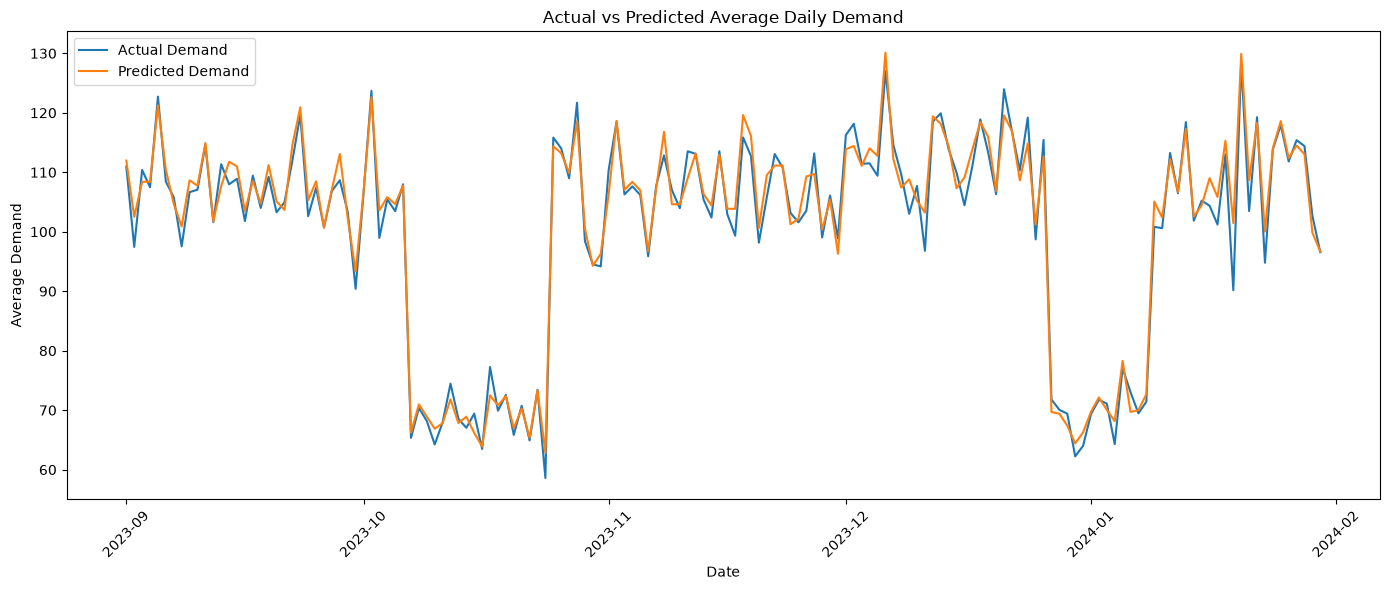

In [28]:
daily_comparison = prediction_results.groupby("Date")[
    ["Actual_Demand", "Predicted_Demand"]
].mean()

plt.figure(figsize=(14, 6))

plt.plot(
    daily_comparison.index,
    daily_comparison["Actual_Demand"],
    label="Actual Demand"
)

plt.plot(
    daily_comparison.index,
    daily_comparison["Predicted_Demand"],
    label="Predicted Demand"
)

plt.xlabel("Date")
plt.ylabel("Average Demand")
plt.title("Actual vs Predicted Average Daily Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
print("Prediction Error Analysis")
print("-------------------------")

print(
    "Average Error:",
    round(prediction_results["Prediction_Error"].mean(), 2)
)

print(
    "Average Absolute Error:",
    round(prediction_results["Prediction_Error"].abs().mean(), 2)
)

print(
    "Maximum Underestimation:",
    round(prediction_results["Prediction_Error"].max(), 2)
)

print(
    "Maximum Overestimation:",
    round(prediction_results["Prediction_Error"].min(), 2)
)

Prediction Error Analysis
-------------------------
Average Error: -0.62
Average Absolute Error: 16.0
Maximum Underestimation: 143.37
Maximum Overestimation: -170.77


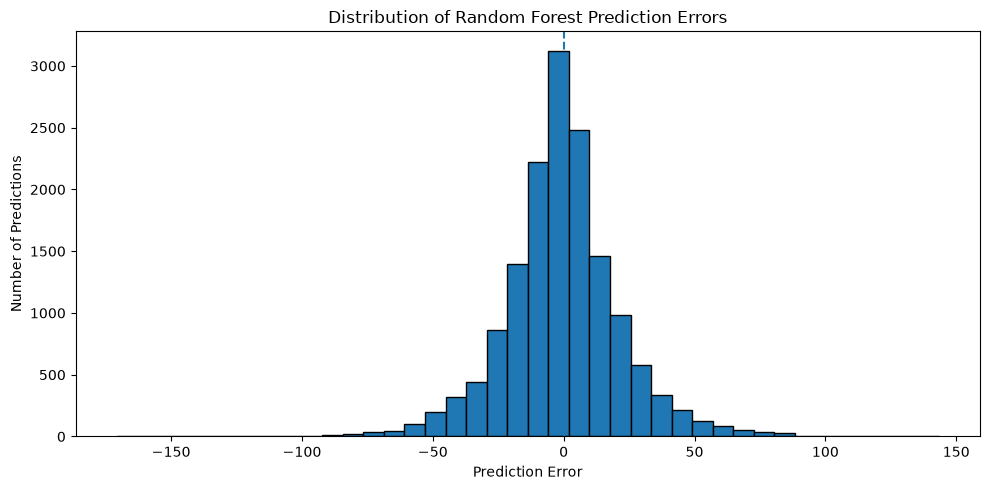

In [30]:
plt.figure(figsize=(10, 5))

plt.hist(
    prediction_results["Prediction_Error"],
    bins=40,
    edgecolor="black"
)

plt.axvline(0, linestyle="--")

plt.xlabel("Prediction Error")
plt.ylabel("Number of Predictions")
plt.title("Distribution of Random Forest Prediction Errors")

plt.tight_layout()
plt.show()

In [31]:
largest_errors = prediction_results.copy()

largest_errors["Absolute_Error"] = (
    largest_errors["Prediction_Error"].abs()
)

largest_errors = largest_errors.sort_values(
    by="Absolute_Error",
    ascending=False
)

display(largest_errors.head(10))

,Date,Actual_Demand,Predicted_Demand,Prediction_Error,Absolute_Error
9510,2023-12-05,4,174.77,-170.77,170.77
1874,2023-09-19,40,189.22,-149.22,149.22
9865,2023-12-08,330,186.63,143.37,143.37
11550,2023-12-25,4,137.53,-133.53,133.53
6711,2023-11-07,32,162.70,-130.70,130.70
6450,2023-11-04,270,146.11,123.89,123.89
13712,2024-01-16,11,132.34,-121.34,121.34
10813,2023-12-18,295,175.30,119.70,119.70
4189,2023-10-12,240,121.85,118.15,118.15
7935,2023-11-19,297,183.58,113.42,113.42


In [32]:
error_details = test_df.iloc[
    largest_errors.head(10).index,
    :
][
    [
        "Date",
        "Store ID",
        "Product ID",
        "Category",
        "Region",
        "Inventory Level",
        "Price",
        "Discount",
        "Promotion",
        "Weather Condition",
        "Seasonality",
        "Epidemic",
        "Demand"
    ]
]

display(error_details)

,Date,Store ID,Product ID,Category,Region,Inventory Level,Price,Discount,Promotion,Weather Condition,Seasonality,Epidemic,Demand
70310,2023-12-05,S004,P0004,Groceries,West,342,27.83,25,1,Sunny,Winter,0,4
62674,2023-09-19,S002,P0004,Groceries,South,175,30.50,15,1,Sunny,Autumn,0,40
70665,2023-12-08,S001,P0009,Clothing,North,198,167.34,0,0,Cloudy,Winter,0,330
72350,2023-12-25,S003,P0010,Groceries,East,197,24.33,10,1,Snowy,Winter,0,4
67511,2023-11-07,S004,P0002,Groceries,West,132,13.52,15,1,Sunny,Autumn,0,32
67250,2023-11-04,S003,P0010,Groceries,East,142,54.98,15,1,Sunny,Autumn,0,270
74512,2024-01-16,S004,P0002,Groceries,West,486,11.59,20,1,Snowy,Winter,0,11
71613,2023-12-18,S003,P0020,Clothing,East,666,92.91,25,1,Sunny,Winter,0,295
64989,2023-10-12,S002,P0015,Clothing,South,207,91.50,10,0,Sunny,Autumn,1,240
68735,2023-11-19,S005,P0010,Groceries,North,320,84.23,15,1,Sunny,Autumn,0,297


In [33]:
print("Demand Distribution")
print("-------------------")

display(df["Demand"].describe())

print("\nLowest 10 demand values:")
display(df.nsmallest(10, "Demand")[["Date", "Category", "Demand"]])

print("\nHighest 10 demand values:")
display(df.nlargest(10, "Demand")[["Date", "Category", "Demand"]])

Demand Distribution
-------------------


count    76000.000000
mean       104.317158
std         46.964801
min          4.000000
25%         71.000000
50%        100.000000
75%        133.000000
max        430.000000
Name: Demand, dtype: float64


Lowest 10 demand values:


,Date,Category,Demand
139,2022-01-02,Groceries,4
1032,2022-01-11,Furniture,4
1833,2022-01-19,Furniture,4
3266,2022-02-02,Groceries,4
4495,2022-02-14,Groceries,4
4729,2022-02-17,Toys,4
6764,2022-03-09,Clothing,4
7224,2022-03-14,Groceries,4
11880,2022-04-29,Toys,4
12698,2022-05-07,Toys,4



Highest 10 demand values:


,Date,Category,Demand
54347,2023-06-28,Groceries,430
21957,2022-08-08,Groceries,378
21838,2022-08-07,Groceries,373
53457,2023-06-19,Groceries,372
60211,2023-08-26,Groceries,370
15929,2022-06-09,Groceries,369
6779,2022-03-09,Toys,361
16218,2022-06-12,Groceries,358
16100,2022-06-11,Groceries,357
53077,2023-06-15,Groceries,351


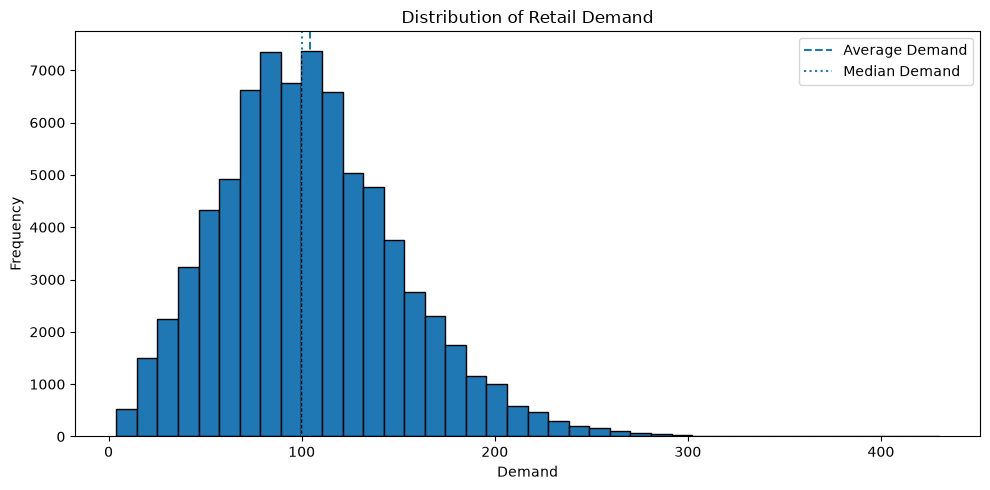

In [34]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["Demand"],
    bins=40,
    edgecolor="black"
)

plt.axvline(
    df["Demand"].mean(),
    linestyle="--",
    label="Average Demand"
)

plt.axvline(
    df["Demand"].median(),
    linestyle=":",
    label="Median Demand"
)

plt.xlabel("Demand")
plt.ylabel("Frequency")
plt.title("Distribution of Retail Demand")
plt.legend()

plt.tight_layout()
plt.show()

In [35]:
category_demand = df.groupby("Category")["Demand"].agg(
    ["mean", "median", "min", "max", "std"]
).round(2)

display(category_demand)

,mean,median,min,max,std
Category,,,,,
Clothing,112.62,109.0,4,330,41.02
Electronics,97.48,95.0,4,339,40.56
Furniture,73.58,72.0,4,214,32.34
Groceries,120.98,116.0,4,430,48.36
Toys,92.61,92.0,4,361,46.17


In [36]:
import seaborn as sns

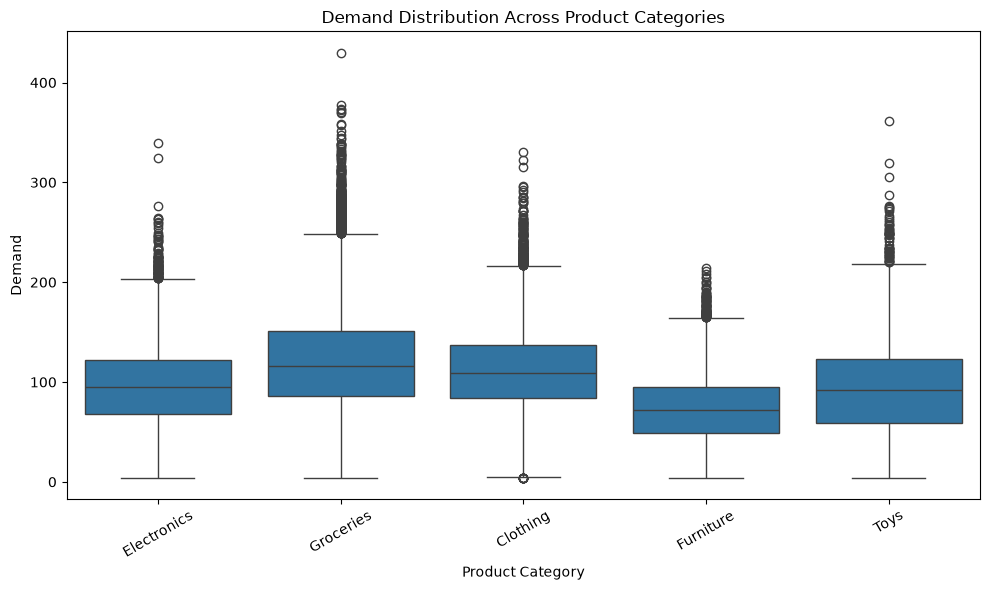

In [37]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Category",
    y="Demand"
)

plt.title("Demand Distribution Across Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Demand")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [38]:
category_variability = df.groupby("Category")["Demand"].agg(
    ["mean", "std"]
)

category_variability["CV (%)"] = (
    category_variability["std"] /
    category_variability["mean"]
) * 100

category_variability = category_variability.round(2)

display(category_variability.sort_values("CV (%)", ascending=False))

,mean,std,CV (%)
Category,,,
Toys,92.61,46.17,49.86
Furniture,73.58,32.34,43.95
Electronics,97.48,40.56,41.61
Groceries,120.98,48.36,39.98
Clothing,112.62,41.02,36.43


In [39]:
region_variability = df.groupby("Region")["Demand"].agg(
    ["mean", "std", "min", "max"]
)

region_variability["CV (%)"] = (
    region_variability["std"] /
    region_variability["mean"]
) * 100

display(region_variability.round(2).sort_values("CV (%)", ascending=False))

,mean,std,min,max,CV (%)
Region,,,,,
North,103.77,47.74,4,430,46.01
West,100.63,45.99,4,370,45.70
East,106.47,47.42,4,361,44.54
South,106.94,45.61,4,351,42.65


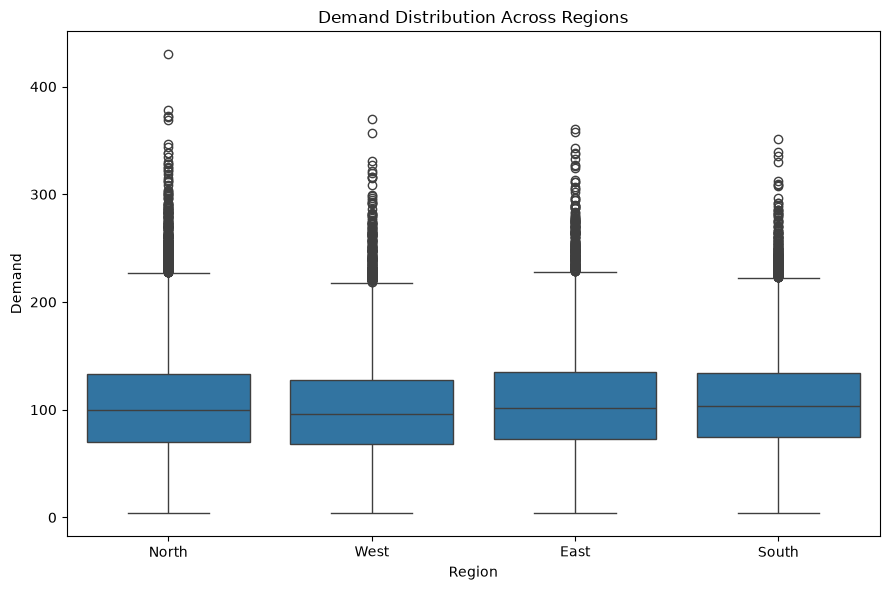

In [40]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Region",
    y="Demand"
)

plt.title("Demand Distribution Across Regions")
plt.xlabel("Region")
plt.ylabel("Demand")

plt.tight_layout()
plt.show()

In [41]:
category_predictions = prediction_results.copy()

category_predictions["Category"] = test_df["Category"].values

category_performance = category_predictions.groupby("Category").apply(
    lambda group: pd.Series({
        "MAE": (group["Actual_Demand"] - group["Predicted_Demand"]).abs().mean(),
        "Average_Actual_Demand": group["Actual_Demand"].mean(),
        "Average_Predicted_Demand": group["Predicted_Demand"].mean()
    }),
    include_groups=False
)

display(category_performance.round(2).sort_values("MAE", ascending=False))

,MAE,Average_Actual_Demand,Average_Predicted_Demand
Category,,,
Groceries,19.34,113.67,114.18
Clothing,19.05,113.91,113.36
Toys,16.04,86.46,89.02
Electronics,14.08,95.59,96.67
Furniture,7.09,72.30,72.38


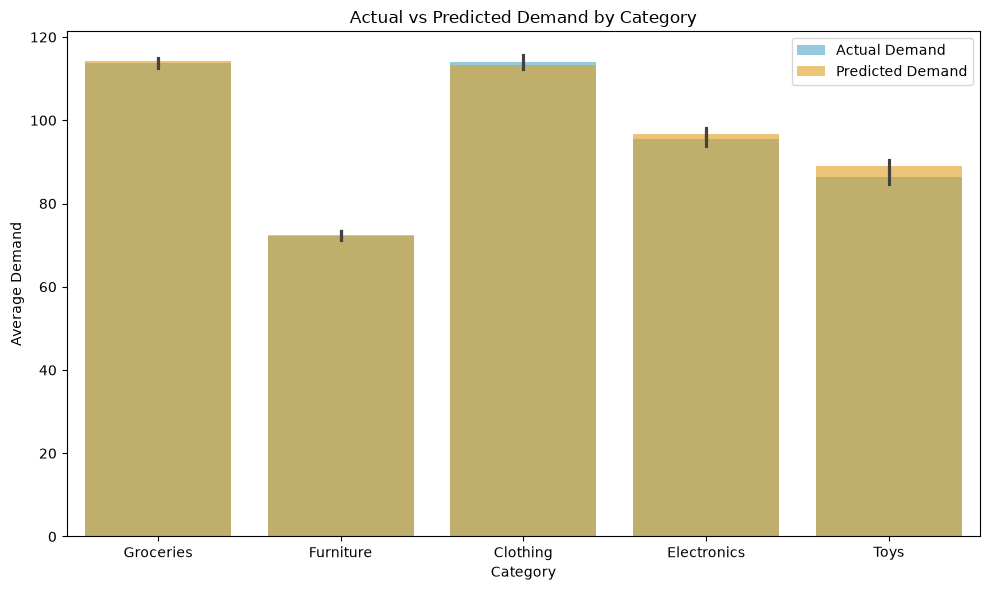

In [42]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_predictions,
    x="Category",
    y="Actual_Demand",
    color="skyblue",
    label="Actual Demand"
)

sns.barplot(
    data=category_predictions,
    x="Category",
    y="Predicted_Demand",
    color="orange",
    alpha=0.6,
    label="Predicted Demand"
)

plt.title("Actual vs Predicted Demand by Category")
plt.xlabel("Category")
plt.ylabel("Average Demand")
plt.legend()

plt.tight_layout()
plt.show()

In [43]:
category_performance["MAPE (%)"] = (
    category_predictions.groupby("Category").apply(
        lambda group: (
            (group["Actual_Demand"] - group["Predicted_Demand"]).abs()
            / group["Actual_Demand"]
        ).mean() * 100,
        include_groups=False
    )
)

display(category_performance.round(2).sort_values("MAPE (%)", ascending=False))

,MAE,Average_Actual_Demand,Average_Predicted_Demand,MAPE (%)
Category,,,,
Toys,16.04,86.46,89.02,28.25
Groceries,19.34,113.67,114.18,27.01
Clothing,19.05,113.91,113.36,22.21
Electronics,14.08,95.59,96.67,20.28
Furniture,7.09,72.30,72.38,14.42


In [44]:
category_predictions["Error"] = (
    category_predictions["Actual_Demand"]
    - category_predictions["Predicted_Demand"]
)

bias_analysis = category_predictions.groupby("Category").agg(
    Average_Error=("Error", "mean"),
    Underestimations=("Error", lambda x: (x > 0).sum()),
    Overestimations=("Error", lambda x: (x < 0).sum())
)

display(bias_analysis.round(2))

,Average_Error,Underestimations,Overestimations
Category,,,
Clothing,0.55,1228,1203
Electronics,-1.07,865,959
Furniture,-0.08,1353,1382
Groceries,-0.51,2876,3204
Toys,-2.56,948,1180


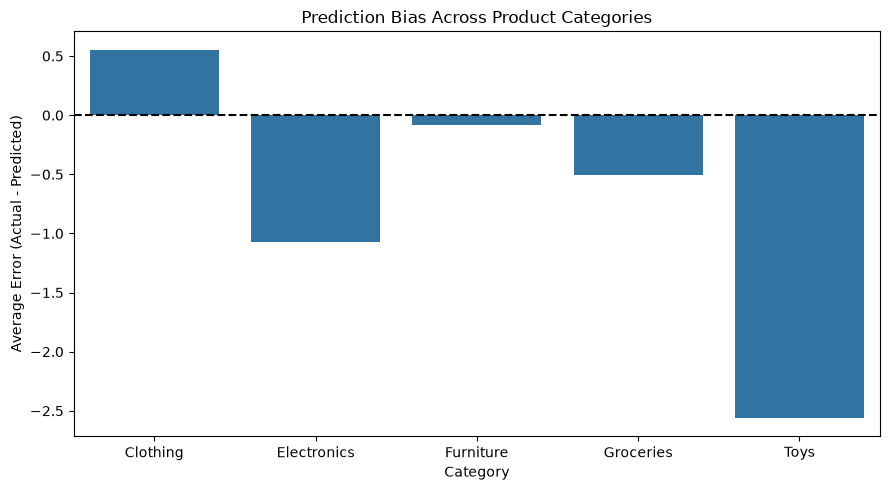

In [45]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=bias_analysis.reset_index(),
    x="Category",
    y="Average_Error"
)

plt.axhline(0, color="black", linestyle="--")

plt.title("Prediction Bias Across Product Categories")
plt.xlabel("Category")
plt.ylabel("Average Error (Actual - Predicted)")

plt.tight_layout()
plt.show()

In [46]:
monthly_predictions = prediction_results.copy()

monthly_predictions["Date"] = pd.to_datetime(
    monthly_predictions["Date"]
)

monthly_predictions["Month"] = (
    monthly_predictions["Date"].dt.to_period("M")
)

monthly_performance = monthly_predictions.groupby("Month").apply(
    lambda group: pd.Series({
        "MAE": (
            group["Actual_Demand"] - group["Predicted_Demand"]
        ).abs().mean(),
        "Average_Actual_Demand": group["Actual_Demand"].mean(),
        "Average_Predicted_Demand": group["Predicted_Demand"].mean()
    }),
    include_groups=False
)

display(monthly_performance.round(2))

,MAE,Average_Actual_Demand,Average_Predicted_Demand
Month,,,
2023-09,15.84,106.78,107.82
2023-10,14.93,84.71,84.91
2023-11,16.08,106.95,107.45
2023-12,16.93,105.29,105.41
2024-01,16.21,98.05,99.30


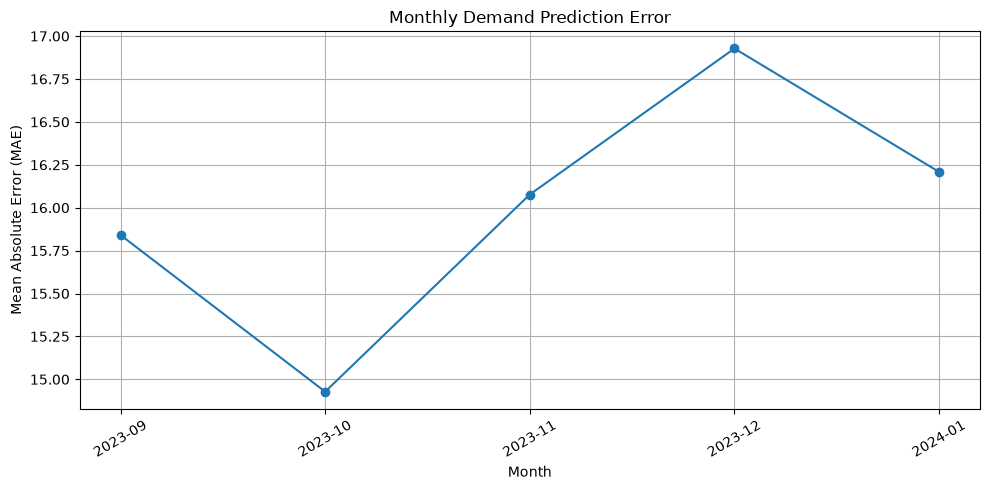

In [47]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_performance.index.astype(str),
    monthly_performance["MAE"],
    marker="o"
)

plt.title("Monthly Demand Prediction Error")
plt.xlabel("Month")
plt.ylabel("Mean Absolute Error (MAE)")
plt.xticks(rotation=30)
plt.grid(True)

plt.tight_layout()
plt.show()

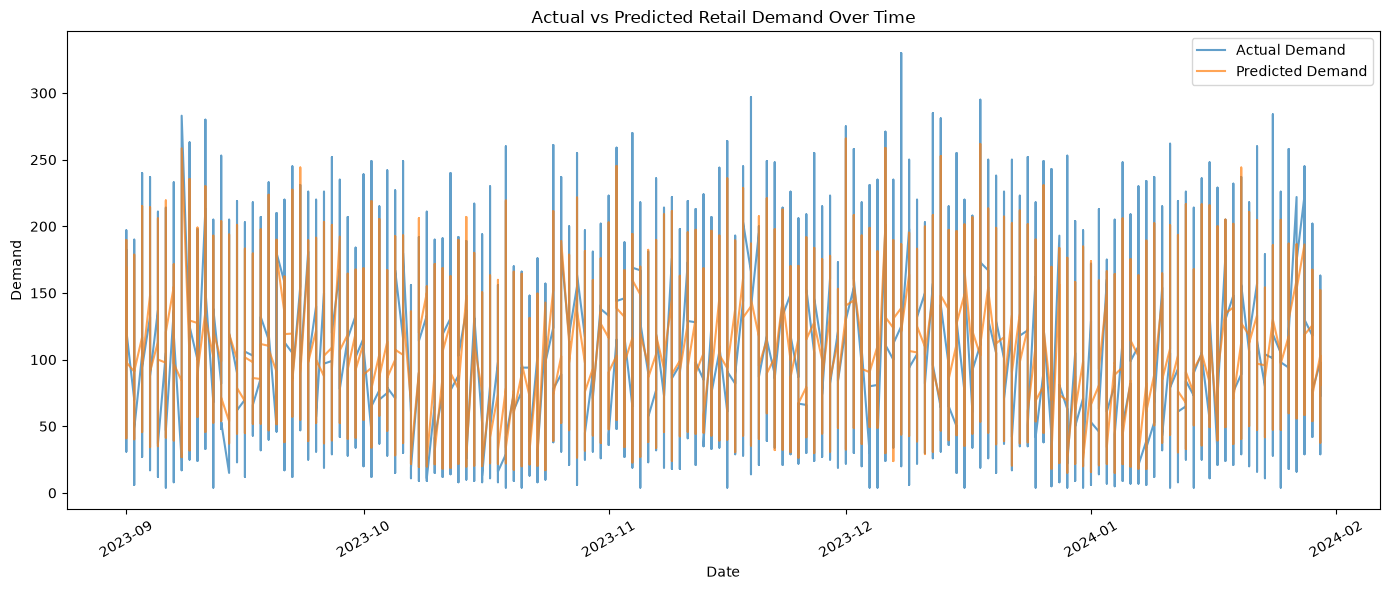

In [48]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_predictions["Date"],
    monthly_predictions["Actual_Demand"],
    label="Actual Demand",
    alpha=0.7
)

plt.plot(
    monthly_predictions["Date"],
    monthly_predictions["Predicted_Demand"],
    label="Predicted Demand",
    alpha=0.7
)

plt.title("Actual vs Predicted Retail Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [49]:
from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(
    X_train_time_encoded,
    y_train_time
)

baseline_pred = baseline_model.predict(X_test_time_encoded)

baseline_mae = mean_absolute_error(
    y_test_time,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test_time, baseline_pred)
)

baseline_r2 = r2_score(
    y_test_time,
    baseline_pred
)

print("Baseline Model Performance")
print("--------------------------")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("R²:", round(baseline_r2, 4))

Baseline Model Performance
--------------------------
MAE: 35.43
RMSE: 44.37
R²: -0.0131


In [50]:
final_comparison = pd.DataFrame({
    "Model": [
        "Baseline Model",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        mae,
        mean_absolute_error(y_test_time, rf_time_pred)
    ],
    "RMSE": [
        baseline_rmse,
        rmse,
        np.sqrt(mean_squared_error(y_test_time, rf_time_pred))
    ],
    "R2": [
        baseline_r2,
        r2,
        r2_score(y_test_time, rf_time_pred)
    ]
})

display(final_comparison.round(4))

,Model,MAE,RMSE,R2
0,Baseline Model,35.4253,44.3739,-0.0131
1,Linear Regression,26.4513,34.2900,0.4676
2,Random Forest,15.9955,22.3422,0.7432


# Conclusion — Demand Prediction

## Project Summary

In this notebook, machine-learning models were developed to estimate retail demand using historical retail data.

The analysis included data preparation, categorical encoding, model training, performance evaluation, chronological validation, prediction-error analysis, and comparison against a baseline model.

## Model Performance

Three models were evaluated:

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Baseline Model | 35.43 | 44.37 | -0.0131 |
| Linear Regression* | 26.45 | 34.29 | 0.4676 |
| Random Forest | 16.00 | 22.34 | 0.7432 |

*Linear Regression was evaluated using a random train-test split, while the Baseline and Random Forest results shown here use a chronological test split.*

The Random Forest model achieved the strongest performance on the chronological test set, with an MAE of 16.00 and an R² of 0.7432.

## Key Findings

1. Random Forest performed substantially better than the baseline model.
2. Price, epidemic status, promotion, and product category were among the most influential model features.
3. Prediction accuracy varied across product categories.
4. Furniture had the lowest category-level MAE, while Groceries had the highest.
5. Monthly prediction errors remained relatively consistent during the test period.
6. The model showed some overestimation and underestimation across categories.

## Business Applications

The demand estimates could help retailers:

- Plan inventory requirements.
- Identify categories requiring closer demand monitoring.
- Support replenishment decisions.
- Investigate periods of unusual demand.
- Provide quantitative inputs for pricing and profitability analysis.

## Limitations

- The dataset does not contain verified actual product costs or profit figures.
- Some feature definitions and their timing relative to demand require further verification.
- The model's results demonstrate performance on a held-out historical period, not guaranteed future forecasting accuracy.
- Correlation and feature importance do not establish causation.
- Further testing is needed before using predictions for real operational decisions.

## Final Outcome

This project demonstrates how Python and machine learning can transform retail data into demand estimates that support business analysis and decision-making.

The Random Forest model will serve as the demand-estimation component for the next stage: **Pricing and Profitability Optimization**.

## Model Reliability and Feature Timing Review

Before interpreting the model as a practical forecasting system, the timing and availability of its input variables must be verified.

The current model uses:

- Store ID and Product ID
- Category and Region
- Inventory Level
- Price and Discount
- Weather Condition
- Promotion
- Competitor Pricing
- Seasonality
- Epidemic status

Some variables may not be known at the time a retailer needs to forecast demand. For example, inventory levels and weather observations may reflect conditions measured after the forecasting decision.

The dataset documentation must also clarify the definitions of Demand and Units Sold.

Therefore, the current model should be interpreted as a historical demand-estimation experiment using observed input variables. Its results should not yet be treated as proof of operational future-forecasting accuracy.

Further validation of feature timing and dataset definitions is required before deployment.

In [51]:
prediction_results.to_csv(
    "../Reports/final_demand_predictions.csv",
    index=False
)

print("Final demand predictions saved successfully!")

Final demand predictions saved successfully!
